In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm
import pygpcca

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
import tifffile

In [3]:
movie = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000].astype(np.float32)

In [4]:
movie -= movie.mean(axis=0)

In [5]:
movie.shape

(10000, 512, 512)

In [6]:
%matplotlib inline

In [7]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2")
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [8]:
rs.selection = (162, 268, 178, 288)

In [10]:
rows, cols = rs.get_selected_indices()
sub = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub.std(axis=0), cmap="gnuplot2")
iw_movie.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [11]:
sub.shape

(10000, 55, 53)

In [12]:
series = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T
series.shape

(2915, 10000)

In [76]:
stsvd = SpaceTimeSVD(series, w=12)

In [77]:
stsvd.compute(k=1)

Computing F, P


100%|█████████████████████████████████████████████████████████████████████████████████████| 2915/2915 [00:00<00:00, 3727.07it/s]


(2915, 10000)
(17490, 9988)


100%|█████████████████████████████████████████████████████████████████████████████████████| 2915/2915 [00:00<00:00, 7318.32it/s]


computing H
Computing Hp
computimng svd of Hp


In [78]:
B = stsvd.adjacency

In [79]:
B = np.abs((B + B.T) / 2)

In [80]:
B

array([[2.83184297e-06, 7.87666965e-07, 3.46153775e-06, ...,
        2.14478171e-05, 2.24531768e-05, 1.56842861e-05],
       [7.87666965e-07, 9.43259336e-07, 1.34710229e-06, ...,
        2.10485653e-05, 8.14222013e-06, 1.45907414e-05],
       [3.46153775e-06, 1.34710229e-06, 3.88283008e-06, ...,
        2.01812647e-05, 2.56410585e-05, 1.04240373e-05],
       ...,
       [2.14478171e-05, 2.10485653e-05, 2.01812647e-05, ...,
        4.61856279e-03, 3.65194380e-03, 1.12129172e-03],
       [2.24531768e-05, 8.14222013e-06, 2.56410585e-05, ...,
        3.65194380e-03, 3.31461390e-03, 1.28516249e-03],
       [1.56842861e-05, 1.45907414e-05, 1.04240373e-05, ...,
        1.12129172e-03, 1.28516249e-03, 1.14563364e-03]])

In [81]:
B.shape

(2915, 2915)

In [82]:
d = 1 / np.sum(B, axis=0)

In [83]:
a = np.diag(d) @ B

In [84]:
import pygpcca as gp

In [85]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

In [90]:
mc = gpcca.minChi(10, 30)

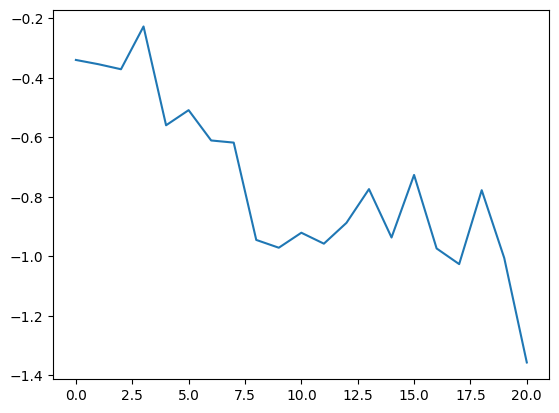

In [91]:
plt.plot(mc)

In [92]:
mc

[np.float64(-0.3394377684230849),
 np.float64(-0.35378330715459766),
 np.float64(-0.37070614164015475),
 np.float64(-0.2268781807736491),
 np.float64(-0.5591307429563337),
 np.float64(-0.5082639661333409),
 np.float64(-0.61020679164176),
 np.float64(-0.6174414640181516),
 np.float64(-0.9446896776247056),
 np.float64(-0.9709351999612025),
 np.float64(-0.9205054720635348),
 np.float64(-0.9572882510666865),
 np.float64(-0.8873569233881938),
 np.float64(-0.7738090989783484),
 np.float64(-0.9365482960205458),
 np.float64(-0.7261930318399904),
 np.float64(-0.9733906865185993),
 np.float64(-1.0260305554939992),
 np.float64(-0.777473748991298),
 np.float64(-1.0056944613460792),
 np.float64(-1.3568351939783823)]

In [87]:
%load_ext viztracer

The viztracer extension is already loaded. To reload it, use:
  %reload_ext viztracer


In [93]:
%%time
gpcca.optimize({'m_min':13, 'm_max':14})

CPU times: user 17.2 s, sys: 45.8 ms, total: 17.2 s
Wall time: 17.1 s


GPCCA[n=2915, n_macrostates=13]

In [94]:
gpcca.memberships.shape

(2915, 13)

In [95]:
gpcca.crispness_values

array([0.18727491, 0.15845305])

In [96]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [97]:
from ipywidgets import HBox

In [98]:
iw = fpl.ImageWidget([img.T for img in labels.T], names=[str(i) for i in range(labels.T.shape[0])], histogram_widget=False, figure_kwargs={"size": (1000, 1000)})
iw2 = fpl.ImageWidget(sub)
HBox([iw.show(), iw2.show()])

RFBOutputContext()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [99]:
from ipywidgets import VBox

In [105]:
iw1 = fpl.ImageWidget(sub)
iw2 = fpl.ImageWidget(sub)

fig = fpl.Figure()

fig[0, 0].add_scatter(np.argwhere(labels.T[4] > 0.1), colors="g", sizes=10, alpha=0.4)
fig[0, 0].add_scatter(np.argwhere(labels.T[5] > 0.15), colors="r", sizes=10, alpha=0.4)

VBox([fig.show(), HBox([iw1.show(), iw2.show()])])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [106]:
fig.renderer.blend_mode = "weighted_plus"

In [101]:
iw1.current_index = {"t": 2288}
iw2.current_index = {"t": 3972}

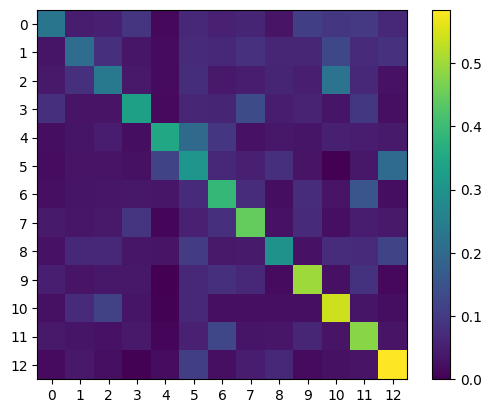

array([[ 2.27261563e-01,  4.46953064e-02,  5.07052057e-02,
         9.09223853e-02,  1.21184100e-02,  6.58308466e-02,
         5.43774298e-02,  6.03136980e-02,  2.96588900e-02,
         1.08931468e-01,  9.24664979e-02,  9.74965440e-02,
         6.52217557e-02],
       [ 3.36658819e-02,  2.08782426e-01,  8.03610764e-02,
         3.59884001e-02,  1.74448849e-02,  7.25952410e-02,
         6.42109313e-02,  8.35022196e-02,  6.31216141e-02,
         6.31230967e-02,  1.26191722e-01,  6.84848818e-02,
         8.25276248e-02],
       [ 3.96612921e-02,  7.93227082e-02,  2.36233188e-01,
         4.06633514e-02,  1.63519674e-02,  7.62305772e-02,
         3.92668050e-02,  4.48649873e-02,  5.97067708e-02,
         4.91624767e-02,  2.23042918e-01,  6.80309820e-02,
         2.74619752e-02],
       [ 7.99061379e-02,  3.12366448e-02,  3.14375497e-02,
         3.31668121e-01,  1.38268483e-02,  6.26797080e-02,
         6.11093877e-02,  1.34266525e-01,  4.41124331e-02,
         5.78418004e-02,  3.30141508e

In [126]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [127]:
gpcca.coarse_grained_transition_matrix[gpcca.coarse_grained_transition_matrix < 0]

array([-0.00045199])

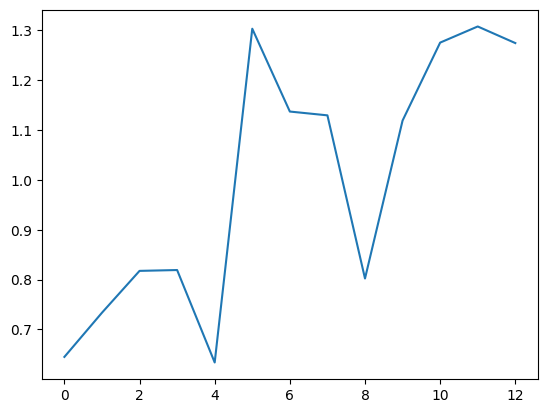

In [128]:
plt.plot(gpcca.coarse_grained_transition_matrix.sum(axis=0))